In [60]:
# Data Understanding
'''
The dataset has the five venue types
1. Bar
2. Coffe House
3. Carry out & Take away
4. Restaurant(<$20)
5. Restaurant($20-$50)

3 questions to answer
1. Right away
2. Later, before the coupon expires
3.No,I do not want the coupon

'''

df=pd.read_csv('data/in-vehicle-coupon-recommendation.csv')
print(f'Shape:{df.shape[0]} rows, {df.shape[1]} columns')
df.head()

Shape:12684 rows, 26 columns


,destination,passanger,weather,temperature,time,coupon,expiration,gender,age,maritalStatus,has_children,education,occupation,income,car,Bar,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Y
0,No Urgent Place,Alone,Sunny,55,2PM,Restaurant(<20),1d,Female,21,Unmarried partner,1,Some college - no degree,Unemployed,$37500 - $49999,NaN,never,never,NaN,4~8,1~3,1,0,0,0,1,1
1,No Urgent Place,Friend(s),Sunny,80,10AM,Coffee House,2h,Female,21,Unmarried partner,1,Some college - no degree,Unemployed,$37500 - $49999,NaN,never,never,NaN,4~8,1~3,1,0,0,0,1,0
2,No Urgent Place,Friend(s),Sunny,80,10AM,Carry out & Take away,2h,Female,21,Unmarried partner,1,Some college - no degree,Unemployed,$37500 - $49999,NaN,never,never,NaN,4~8,1~3,1,1,0,0,1,1
3,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,2h,Female,21,Unmarried partner,1,Some college - no degree,Unemployed,$37500 - $49999,NaN,never,never,NaN,4~8,1~3,1,1,0,0,1,0
4,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,1d,Female,21,Unmarried partner,1,Some college - no degree,Unemployed,$37500 - $49999,NaN,never,never,NaN,4~8,1~3,1,1,0,0,1,0


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns',None)
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = [8,5]

In [4]:
df.info

<bound method DataFrame.info of            destination  passanger weather  temperature  time  \
0      No Urgent Place      Alone   Sunny           55   2PM   
1      No Urgent Place  Friend(s)   Sunny           80  10AM   
2      No Urgent Place  Friend(s)   Sunny           80  10AM   
3      No Urgent Place  Friend(s)   Sunny           80   2PM   
4      No Urgent Place  Friend(s)   Sunny           80   2PM   
...                ...        ...     ...          ...   ...   
12679             Home    Partner   Rainy           55   6PM   
12680             Work      Alone   Rainy           55   7AM   
12681             Work      Alone   Snowy           30   7AM   
12682             Work      Alone   Snowy           30   7AM   
12683             Work      Alone   Sunny           80   7AM   

                      coupon expiration  gender age      maritalStatus  \
0            Restaurant(<20)         1d  Female  21  Unmarried partner   
1               Coffee House         2h  Female  21

In [6]:
# 1.1 Missing values

missing=df.isna().sum()
missing=missing[missing>0].sort_values(ascending=False)
missing_pct=(missing/len(df) * 100).round(2)
pd.DataFrame({'missing_count': missing, 'missing_pct': missing_pct})

,missing_count,missing_pct
car,12576,99.15
CoffeeHouse,217,1.71
Restaurant20To50,189,1.49
CarryAway,151,1.19
RestaurantLessThan20,130,1.02
Bar,107,0.84


In [7]:
# Cleaning Decisions

# drop the empty car column
df=df.drop(columns=['car'])
freq_cols=['Bar','CoffeeHouse','CarryAway','RestaurantLessThan20','Restaurant20To50']

before = len(df)
df=df.dropna(subset=freq_cols)

print(f'Dropped {before-len(df)} rows with missing frequency-of-visit data ({(before - len(df))/before:.1%})')

Dropped 605 rows with missing frequency-of-visit data (4.8%)


In [12]:
# Coupon Acceptance
overall_rate = df['Y'].mean()
print(f'Overall coupon acceptance rate: {overall_rate:1%}')

Overall coupon acceptance rate: 56.933521%


ValueError: cannot convert float NaN to integer

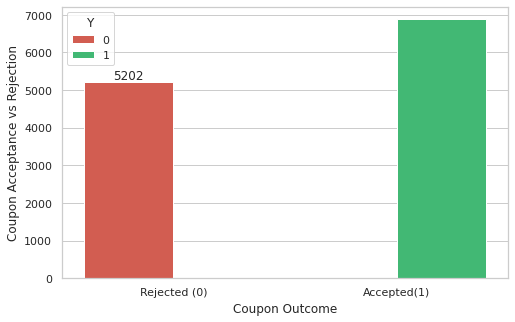

In [8]:
fig,ax=plt.subplots()
sns.countplot(data=df, x='Y', hue='Y',palette=['#e74c3c','#2ecc71'], ax=ax)
ax.set_xticklabels(['Rejected (0)','Accepted(1)'])
ax.set_xlabel('Coupon Outcome')
ax.set_ylabel('Number of Respondents')
ax.set_ylabel('Coupon Acceptance vs Rejection')
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}',(p.get_x() + p.get_width()/2,p.get_height()),ha='center', va='bottom')
plt.tight_layout()
plt.show()

In [9]:
acceptance_by_coupon = df.groupby('coupon')['Y'].mean().sort_values(ascending=False)
acceptance_by_coupon

coupon
Carry out & Take away    0.737719
Restaurant(<20)          0.709009
Coffee House             0.496331
Restaurant(20-50)        0.446013
Bar                      0.411918
Name: Y, dtype: float64

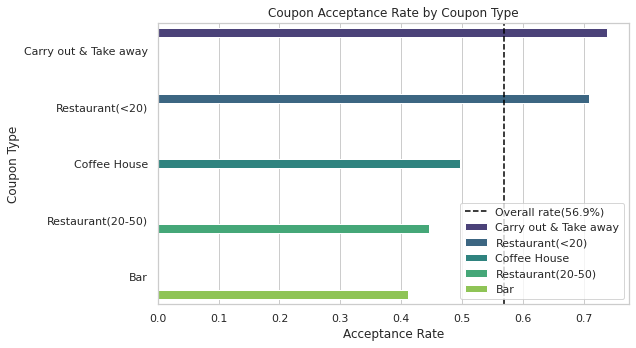

In [13]:
fig,ax=plt.subplots(figsize=(9,5))
order = acceptance_by_coupon.index
sns.barplot(x=acceptance_by_coupon.values, y=order, hue=order,palette='viridis',ax=ax)
ax.axvline(overall_rate, color='black', linestyle='--', label=f'Overall rate({overall_rate:.1%})')
ax.set_xlabel('Acceptance Rate')
ax.set_ylabel('Coupon Type')
ax.set_title('Coupon Acceptance Rate by Coupon Type')
ax.legend()
plt.tight_layout()
plt.show()

In [14]:
# Deep Dive: Bar Coupons
# how many of the frequently goes to Bar
bar_df=df[df['coupon'] == 'Bar'].copy()
print(f'Bar coupon subset shape: {bar_df.shape}')

bar_rate=bar_df['Y'].mean()
print(f'Bar coupon:{bar_rate:.1%}')

Bar coupon subset shape: (1913, 25)
Bar coupon:41.2%


In [17]:
# rate by frequency of bar visits
bar_order = ['never','less1','1~3','4-8','gt8']
bar_df['Bar']=pd.Categorical(bar_df['Bar'], categories=bar_order, ordered=True)
bar_visit_rate=bar_df.groupby('Bar', observed=True)['Y'].mean()
bar_visit_rate


Bar
never    0.189086
less1    0.446655
1~3      0.646438
gt8      0.717391
Name: Y, dtype: float64

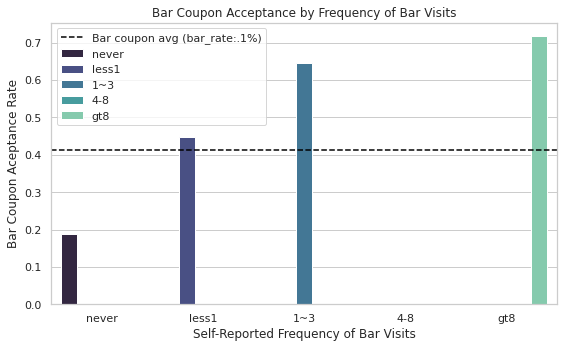

In [25]:
fig,ax=plt.subplots()
sns.barplot(x=bar_visit_rate.index,y=bar_visit_rate.values,hue=bar_visit_rate.index,palette='mako',ax=ax)
ax.axhline(bar_rate,color='black',linestyle='--',label=f'Bar coupon avg (bar_rate:.1%)')
ax.set_xlabel('Self-Reported Frequency of Bar Visits')
ax.set_ylabel('Bar Coupon Aceptance Rate')
ax.set_title('Bar Coupon Acceptance by Frequency of Bar Visits')
ax.legend()
plt.tight_layout()
plt.show()

Frequent bar visitors:572 rows
Acceptance rate among bar-goers:68.5%


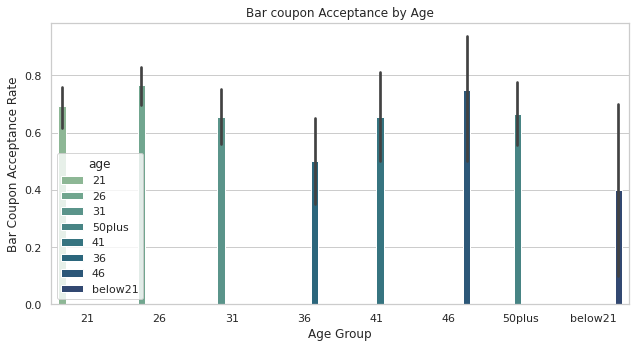

In [34]:
# frequent visitor to the bar who accept vs reject 
frequent_bar = bar_df[~bar_df['Bar'].isin(['never','less1'])].copy()
print(f'Frequent bar visitors:{frequent_bar.shape[0]} rows')
print(f'Acceptance rate among bar-goers:{frequent_bar["Y"].mean():.1%}')
age_order=sorted(frequent_bar['age'].unique(), key=lambda x: (len(x),x))
fig,ax=plt.subplots(figsize=(9,5))
sns.barplot(data=frequent_bar,x='age',y='Y',order=age_order, hue='age',palette='crest', estimator=np.mean, ax=ax)
ax.set_xlabel('Age Group')
ax.set_ylabel('Bar Coupon Acceptance Rate')
ax.set_title('Bar coupon Acceptance by Age')
plt.tight_layout()
plt.show()

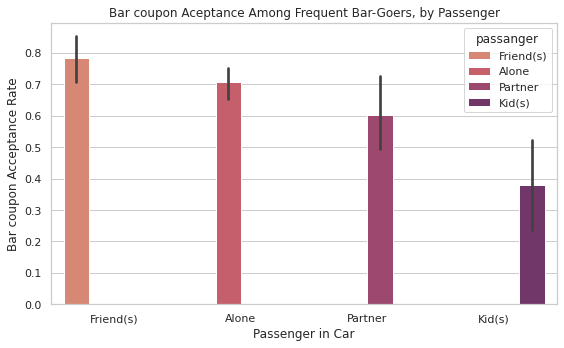

In [40]:
# Bar frequent goes by Passenger
fig,ax=plt.subplots(figsize=(8,5))
sns.barplot(data=frequent_bar,x='passanger',y='Y', hue='passanger',palette='flare',estimator=np.mean, ax=ax)
ax.set_xlabel('Passenger in Car')
ax.set_ylabel('Bar coupon Acceptance Rate')
ax.set_title('Bar coupon Aceptance Among Frequent Bar-Goers, by Passenger')
plt.tight_layout()
plt.show()

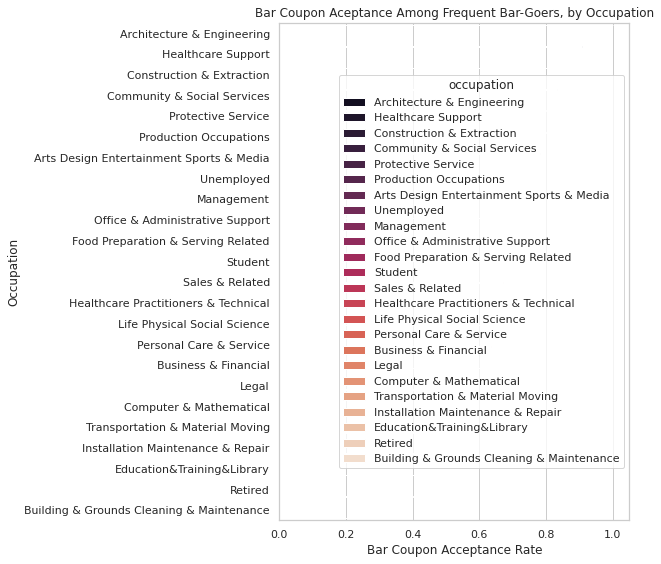

In [47]:
# Occupation and Marital Status

occ_rate=frequent_bar.groupby('occupation')['Y'].mean().sort_values(ascending=False)
fig,ax=plt.subplots(figsize=(9,8))
sns.barplot(x=occ_rate.values, y=occ_rate.index, hue=occ_rate.index, palette='rocket', ax=ax, legend=False)
ax.set_xlabel('Bar Coupon Acceptance Rate')
ax.set_ylabel('Occupation')
ax.set_title('Bar Coupon Aceptance Among Frequent Bar-Goers, by Occupation')
plt.tight_layout()
plt.show()


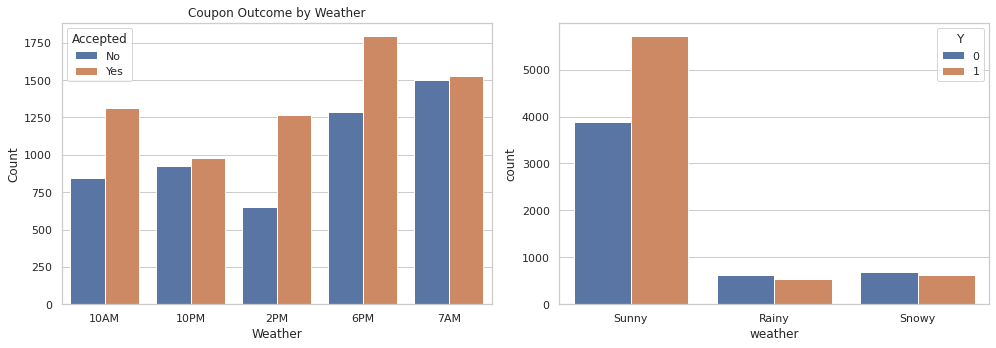

In [53]:
# Accepted vs Rejected
fig,axes=plt.subplots(1,2, figsize=(14,5))
sns.countplot(data=df, x='time',hue='Y', order=sorted(df['time'].unique()), ax=axes[0])
axes[0].set_title('Coupon Outcome by Time of Day')
axes[0].set_xlabel('Time of Day')
axes[0].set_ylabel('Count')
axes[0].legend(title='Accepted', labels=['No','Yes'])

sns.countplot(data=df, x='weather', hue='Y', ax=axes[1])
axes[0].set_title('Coupon Outcome by Weather')
axes[0].set_xlabel('Weather')
axes[0].set_ylabel('Count')
axes[0].legend(title='Accepted', labels=['No','Yes'])

plt.tight_layout()
plt.show()

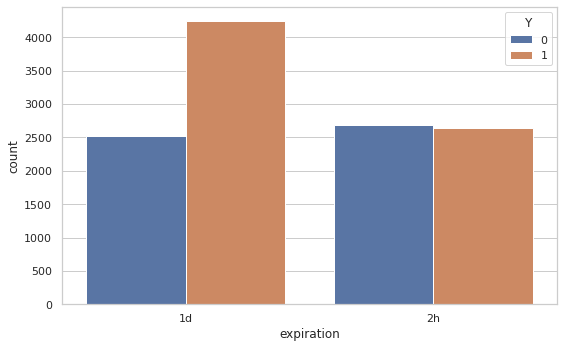

expiration
1d    0.627811
2h    0.495018
Name: Y, dtype: float64


In [55]:
fig,ax=plt.subplots(figsize=(8,5))
sns.countplot(data=df,x='expiration',hue='Y', ax=ax)
axes[0].set_title('Coupon Outcome by Expiration Window')
axes[0].set_xlabel('Coupon Expiration')
axes[0].set_ylabel('Count')
axes[0].legend(title='Accepted', labels=['No','Yes'])

plt.tight_layout()
plt.show()

exp_rate=df.groupby('expiration')['Y'].mean()
print(exp_rate)

In [57]:
num_cols=['temperature','has_children','toCoupon_GEQ5min','toCoupon_GEQ15min','toCoupon_GEQ25min','direction_same','direction_opp']
corr=df[num_cols+['Y']].corr()['Y'].sort_values(ascending=False)
corr

Y                    1.000000
temperature          0.056646
direction_same       0.014361
direction_opp       -0.014361
has_children        -0.048333
toCoupon_GEQ15min   -0.081711
toCoupon_GEQ25min   -0.100542
toCoupon_GEQ5min          NaN
Name: Y, dtype: float64

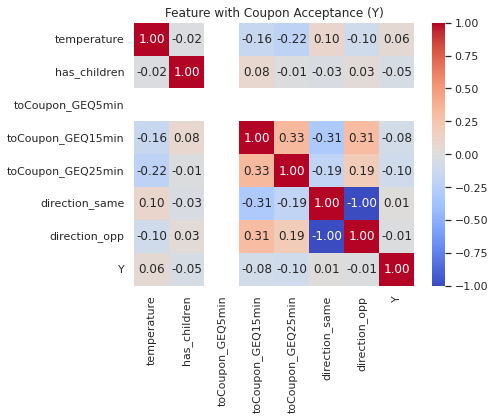

In [59]:
fig,ax=plt.subplots(figsize=(7,6))
sns.heatmap(df[num_cols + ['Y']].corr(),annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax)
ax.set_title('Feature with Coupon Acceptance (Y)')
plt.tight_layout()
plt.show()